In [1]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Upload the customer dataset

from google.colab import files

uploaded = files.upload()


Saving Mall_Customers.csv to Mall_Customers.csv


In [3]:

# Step 3: Load and inspect customer data

df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset shape:
(200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [4]:

# Step 4: Select features for customer segmentation

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print("Selected features:")
display(X.head())

print("\nSummary statistics:")
display(X.describe())

print("\nData types:")
print(X.dtypes)


Selected features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Summary statistics:


,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000
mean,60.560000,50.200000
std,26.264721,25.823522
min,15.000000,1.000000
25%,41.500000,34.750000
50%,61.500000,50.000000
75%,78.000000,73.000000
max,137.000000,99.000000



Data types:
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


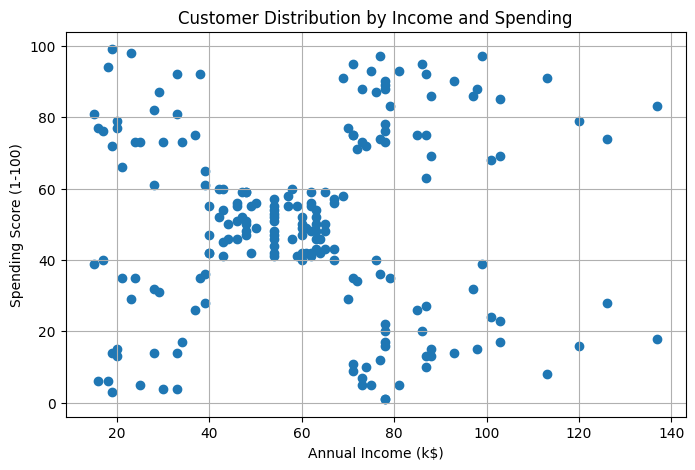

In [5]:

# Step 5: Visualize customer data

plt.figure(figsize=(8, 5))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)']
)

plt.title('Customer Distribution by Income and Spending')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True)
plt.show()


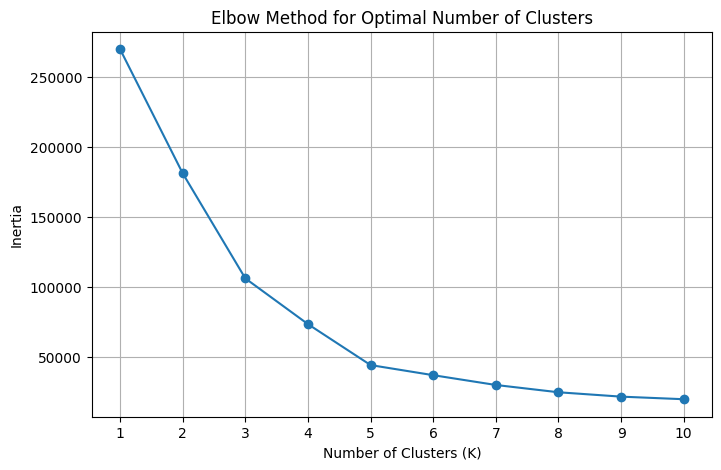

In [6]:

# Step 6: Elbow Method

inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker='o')

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [7]:

# Step 7: Apply K-Means clustering

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(X)

print("K-Means model trained successfully!")
print("\nNumber of customers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

print("\nSample customer data with cluster labels:")
display(df.head(10))


K-Means model trained successfully!

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Sample customer data with cluster labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


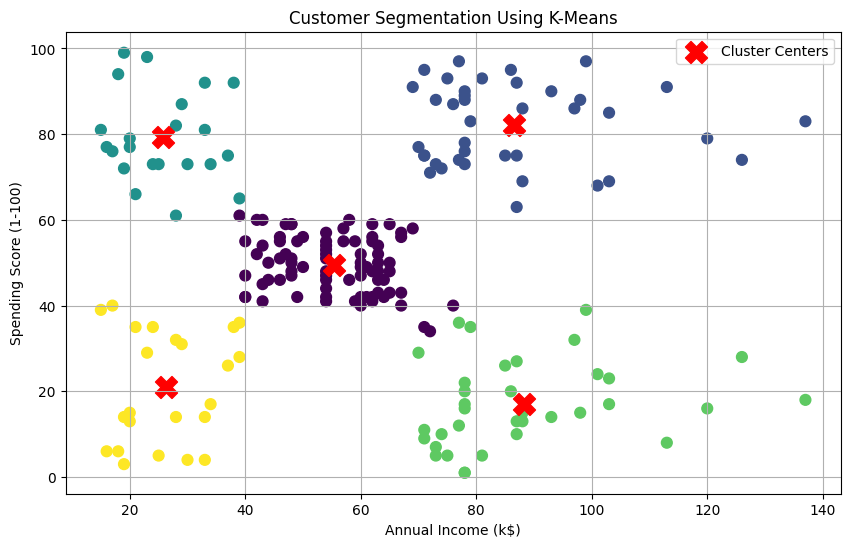

In [8]:

# Step 8: Visualize customer clusters

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    s=60
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=250,
    c='red',
    label='Cluster Centers'
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True)
plt.show()


In [9]:

# Step 9: Analyze each customer segment

cluster_summary = df.groupby('Cluster').agg(
    Number_of_Customers=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending_Score=('Spending Score (1-100)', 'mean')
).round(2)

print("Customer Segment Analysis:")
display(cluster_summary)


Customer Segment Analysis:


,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [10]:

# Step 11: Evaluate clustering quality

score = silhouette_score(X, df['Cluster'])

print("Silhouette Score:", round(score, 4))

if score >= 0.7:
    print("Interpretation: Strongly separated clusters")
elif score >= 0.5:
    print("Interpretation: Reasonably well-separated clusters")
elif score >= 0.25:
    print("Interpretation: Some cluster structure exists, but overlap may remain")
else:
    print("Interpretation: Clusters may overlap significantly")


Silhouette Score: 0.5539
Interpretation: Reasonably well-separated clusters


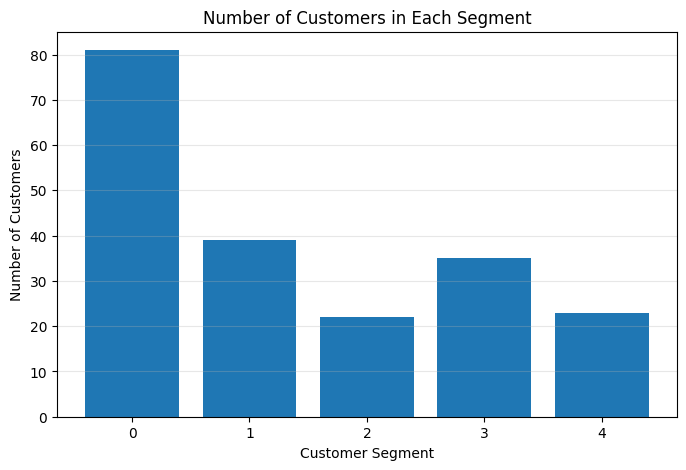

In [11]:

# Step 12: Customer count by segment

cluster_counts = df['Cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.3)
plt.show()


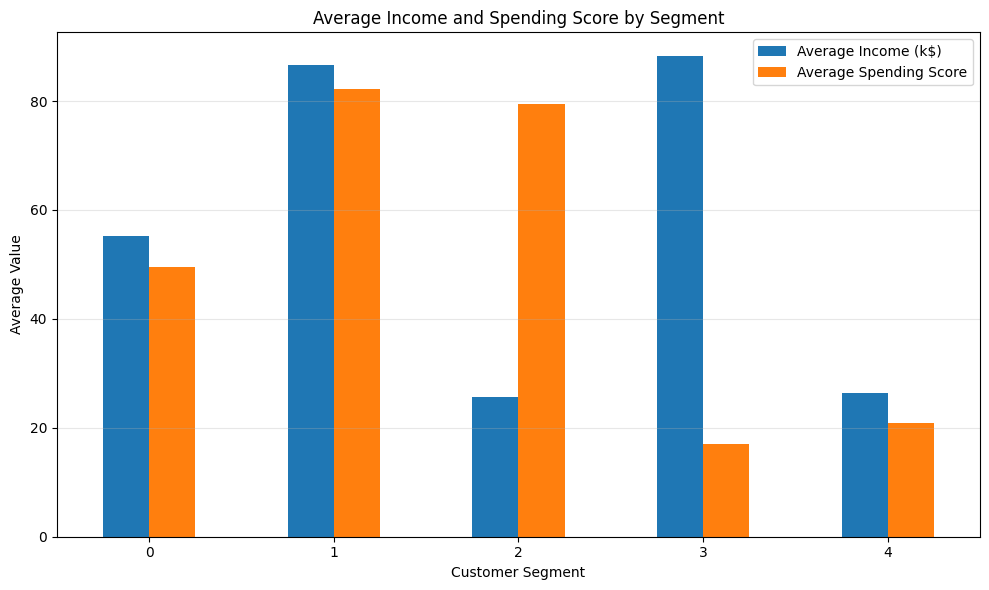

In [12]:

# Step 13: Compare segment characteristics

cluster_summary[['Average_Income', 'Average_Spending_Score']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Income and Spending Score by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(['Average Income (k$)', 'Average Spending Score'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

# Step 14: Export project results

df.to_csv('Customer_Segmentation_Results.csv', index=False)
cluster_summary.to_csv('Customer_Segment_Summary.csv')

print("Project results saved successfully!")
print("1. Customer_Segmentation_Results.csv")
print("2. Customer_Segment_Summary.csv")


Project results saved successfully!
1. Customer_Segmentation_Results.csv
2. Customer_Segment_Summary.csv


In [14]:

from google.colab import files

files.download('Customer_Segmentation_Results.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

files.download('Customer_Segment_Summary.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>